In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from pathlib import Path
from IPython.display import display

plt.rcParams["figure.figsize"] = (12, 7)
plt.rcParams["axes.grid"] = False

In [2]:
folder_data = Path.cwd()

nama_file = "chlorophyll_a_daily_ntt.nc"

file_data = folder_data / nama_file

if not file_data.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {file_data}")

print("File ditemukan:", file_data)

File ditemukan: d:\KULIAH\Semester5\PBLKLIMTROP\AnalisisClorofil-A\chlorophyll_a_daily_ntt.nc


In [3]:
ds = xr.open_dataset(file_data)

display(ds)

<xarray.Dataset> Size: 2GB
Dimensions:     (time: 7669, lat: 144, lon: 240)
Coordinates:
  * time        (time) datetime64[ns] 61kB 2000-01-01 2000-01-02 ... 2020-12-31
  * lat         (lat) float64 1kB -7.021 -7.062 -7.104 ... -12.9 -12.94 -12.98
  * lon         (lon) float64 2kB 117.5 117.6 117.6 117.6 ... 127.4 127.4 127.5
Data variables:
    chlor_a     (time, lat, lon) float32 1GB ...
    total_nobs  (time, lat, lon) float32 1GB ...
Attributes: (12/49)
    Conventions:                    CF-1.7
    Metadata_Conventions:           Unidata Dataset Discovery v1.0
    cdm_data_type:                  Grid
    comment:                        See summary attribute
    creation_date:                  20220517T155248Z
    creator_email:                  help@esa-oceancolour-cci.org
    ...                             ...
    id:                             ESACCI-OC-L3S-CHLOR_A-MERGED-1D_DAILY_4km...
    summary:                        Data products generated for C3S using the...
    region:                         Bounding box NTT: lon 117.5–127.5°E, lat ...
    created_by:                     Notebook 1 - Persiapan dan Penggabungan Data
    created_date:                   2026-10-29 15:47:59
    note:                           Data harian asli dipertahankan. Missing v...

In [4]:
print("Koordinat yang tersedia:")

for coord in ds.coords:
    print(
        f"{coord}:",
        ds[coord].values[:5] if ds[coord].ndim == 1 else ds[coord].shape
    )

Koordinat yang tersedia:
lat: [-7.02083333 -7.0625     -7.10416667 -7.14583333 -7.1875    ]
lon: [117.52083333 117.5625     117.60416667 117.64583333 117.6875    ]
time: ['2000-01-01T00:00:00.000000000' '2000-01-02T00:00:00.000000000'
 '2000-01-03T00:00:00.000000000' '2000-01-04T00:00:00.000000000'
 '2000-01-05T00:00:00.000000000']


In [5]:
koordinat_waktu = "time"

waktu = pd.to_datetime(ds[koordinat_waktu].values)

print("Tanggal awal :", waktu.min())
print("Tanggal akhir:", waktu.max())
print("Jumlah data  :", len(waktu))
print("Jumlah hari unik:", pd.Series(waktu).nunique())

Tanggal awal : 2000-01-01 00:00:00
Tanggal akhir: 2020-12-31 00:00:00
Jumlah data  : 7669
Jumlah hari unik: 7669


In [6]:
variabel_chl = "chlor_a"

chl = ds[variabel_chl]

print("Statistik Klorofil-a:")
print("Minimum :", float(chl.min(skipna=True)))
print("Maksimum:", float(chl.max(skipna=True)))
print("Rata-rata:", float(chl.mean(skipna=True)))
print("Median  :", float(chl.median(skipna=True)))
print("Jumlah nilai kosong:", int(chl.isnull().sum()))
print("Jumlah nilai valid :", int(chl.count()))

Statistik Klorofil-a:
Minimum : 0.0010000000474974513
Maksimum: 93.8349838256836
Rata-rata: 0.2932835519313812
Median  : 0.2071431279182434
Jumlah nilai kosong: 163301341
Jumlah nilai valid : 101739299


In [7]:
# ============================================================
# FUNGSI FILTER OUTLIER MENGGUNAKAN METODE IQR
# ============================================================

def filter_iqr_per_grid(data, faktor=1.5):
    """
    Menghilangkan outlier klorofil-a menggunakan metode IQR.

    Perhitungan Q1 dan Q3 dilakukan secara temporal
    pada setiap grid secara terpisah.

    Parameter:
    data   : DataArray klorofil-a dengan dimensi time, lat, lon
    faktor : Pengali IQR (default 1.5)

    Return:
    DataArray dengan nilai outlier diganti NaN.
    """

    # Kuartil pertama dan ketiga untuk setiap grid
    q1 = data.quantile(
        0.25,
        dim="time",
        skipna=True
    )

    q3 = data.quantile(
        0.75,
        dim="time",
        skipna=True
    )

    # Menghitung rentang interkuartil
    iqr = q3 - q1

    # Menentukan batas bawah dan atas
    batas_bawah = q1 - faktor * iqr
    batas_atas = q3 + faktor * iqr

    # Mempertahankan nilai yang berada dalam batas IQR
    data_filtered = data.where(
        (data >= batas_bawah) &
        (data <= batas_atas)
    )

    # Menghitung jumlah nilai yang dihilangkan
    jumlah_awal = int(data.count().values)
    jumlah_akhir = int(data_filtered.count().values)
    jumlah_outlier = jumlah_awal - jumlah_akhir

    persentase_outlier = (
        jumlah_outlier / jumlah_awal * 100
        if jumlah_awal > 0 else 0
    )

    print("Filter IQR selesai.")
    print("Jumlah data valid awal :", jumlah_awal)
    print("Jumlah outlier         :", jumlah_outlier)
    print("Persentase outlier     :", round(persentase_outlier, 2), "%")
    print("Jumlah data valid akhir:", jumlah_akhir)

    return data_filtered

In [8]:

# ==========================================
# PEMOTONGAN KOORDINAT WILAYAH NTT
# ==========================================

# Batas koordinat wilayah analisis
lon_min, lon_max = 118, 126
lat_min, lat_max = -12, -7.5

# Mendeteksi nama koordinat
lon_name = next(
    (c for c in ["lon", "longitude"] if c in chl.coords),
    None
)

lat_name = next(
    (c for c in ["lat", "latitude"] if c in chl.coords),
    None
)

if lon_name is None or lat_name is None:
    raise ValueError("Koordinat longitude/latitude tidak ditemukan.")

# Menyimpan ukuran data sebelum pemotongan
print("Dimensi sebelum pemotongan:", chl.shape)

# Memotong data berdasarkan koordinat spasial
chl = chl.where(
    (chl[lon_name] >= lon_min) &
    (chl[lon_name] <= lon_max) &
    (chl[lat_name] >= lat_min) &
    (chl[lat_name] <= lat_max),
    drop=True
)

print("Dimensi setelah pemotongan:", chl.shape)
print("Longitude:", lon_min, "sampai", lon_max)
print("Latitude :", lat_min, "sampai", lat_max)

print("Pemotongan koordinat selesai.")


Dimensi sebelum pemotongan: (7669, 144, 240)
Dimensi setelah pemotongan: (7669, 108, 192)
Longitude: 118 sampai 126
Latitude : -12 sampai -7.5
Pemotongan koordinat selesai.


In [9]:
tanggal_mulai = "2016-02-07"
tanggal_akhir = "2016-12-02"

chl_periode = chl.sel(
    time=slice(tanggal_mulai, tanggal_akhir)
)

if chl_periode.sizes["time"] == 0:
    raise ValueError("Tidak terdapat data pada rentang waktu yang dipilih.")

print("Periode analisis:", tanggal_mulai, "sampai", tanggal_akhir)
print("Jumlah data harian:", chl_periode.sizes["time"])

Periode analisis: 2016-02-07 sampai 2016-12-02
Jumlah data harian: 300


In [10]:
chl_mean_grid = chl_periode.mean(
    dim="time",
    skipna=True
)

print("Perhitungan rata-rata setiap grid selesai (tanpa filter IQR).")
print("Dimensi hasil:", chl_mean_grid.dims)

Perhitungan rata-rata setiap grid selesai (tanpa filter IQR).
Dimensi hasil: ('lat', 'lon')


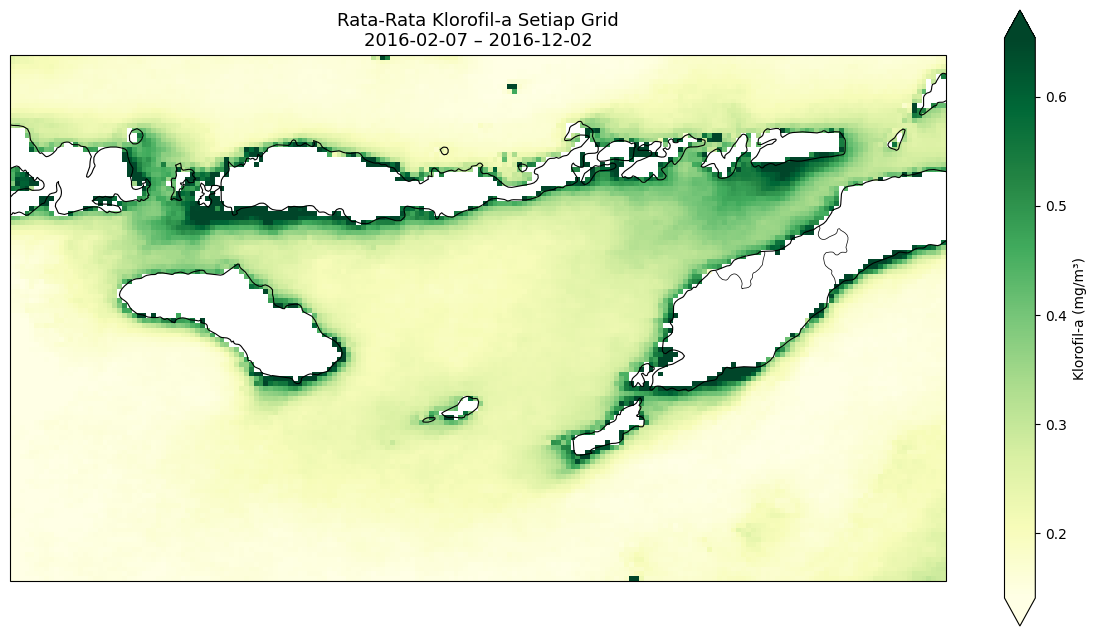

In [11]:
fig = plt.figure(figsize=(12, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

# BATAS KOORDINAT SESUAI GAMBAR
ax.set_extent([118, 126, -12, -7.5], crs=ccrs.PlateCarree())
    
chl_mean_grid.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="YlGn",
    robust=True,
    cbar_kwargs={
        "label": "Klorofil-a (mg/m³)",
        "shrink": 0.8
    }
)

ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

ax.set_title(
    f"Rata-Rata Klorofil-a Setiap Grid\n{tanggal_mulai} – {tanggal_akhir}",
    fontsize=13
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [12]:
# ==========================================
# CELL 7 - PERHITUNGAN ANOMALI KLOROFIL-A
# ==========================================

# Konversi tanggal menjadi datetime
tanggal_awal = pd.to_datetime(tanggal_mulai)
tanggal_akhir_dt = pd.to_datetime(tanggal_akhir)

# Pastikan rentang tanggal tidak terbalik
if tanggal_awal > tanggal_akhir_dt:
    raise ValueError("Tanggal mulai harus sebelum tanggal akhir.")

# Mengambil data historis untuk baseline
tahun_awal_baseline = int(chl.time.dt.year.min())
tahun_akhir_baseline = int(chl.time.dt.year.max())

# Mengambil bulan dan tanggal yang sama pada setiap tahun
bulan_awal = tanggal_awal.month
bulan_akhir = tanggal_akhir_dt.month

hari_awal = tanggal_awal.day
hari_akhir = tanggal_akhir_dt.day

mask_kalender = (
    (chl.time.dt.month >= bulan_awal) &
    (chl.time.dt.month <= bulan_akhir)
)

# Menangani periode yang melewati pergantian tahun
if bulan_awal > bulan_akhir:
    mask_kalender = (
        (chl.time.dt.month >= bulan_awal) |
        (chl.time.dt.month <= bulan_akhir)
    )

baseline_data = chl.where(mask_kalender, drop=True)

# Mengambil rentang tahun baseline
baseline_data = baseline_data.where(
    (baseline_data.time.dt.year >= tahun_awal_baseline) &
    (baseline_data.time.dt.year <= tahun_akhir_baseline),
    drop=True
)

# Menghitung rata-rata klimatologi setiap grid
baseline_mean = baseline_data.mean(
    dim="time",
    skipna=True
)

# Baseline tetap mengikuti logika notebook awal: bulan target pada seluruh tahun data,
# termasuk tahun target; hanya filtering IQR yang dihapus.

# Menghitung anomali setiap grid
chl_anomali = chl_mean_grid - baseline_mean

print("Perhitungan anomali selesai.")
print("Periode analisis:", tanggal_mulai, "-", tanggal_akhir)
print("Periode baseline:", tahun_awal_baseline, "-", tahun_akhir_baseline)
print("Jumlah grid:", chl_anomali.size)

Perhitungan anomali selesai.
Periode analisis: 2016-02-07 - 2016-12-02
Periode baseline: 2000 - 2020
Jumlah grid: 20736


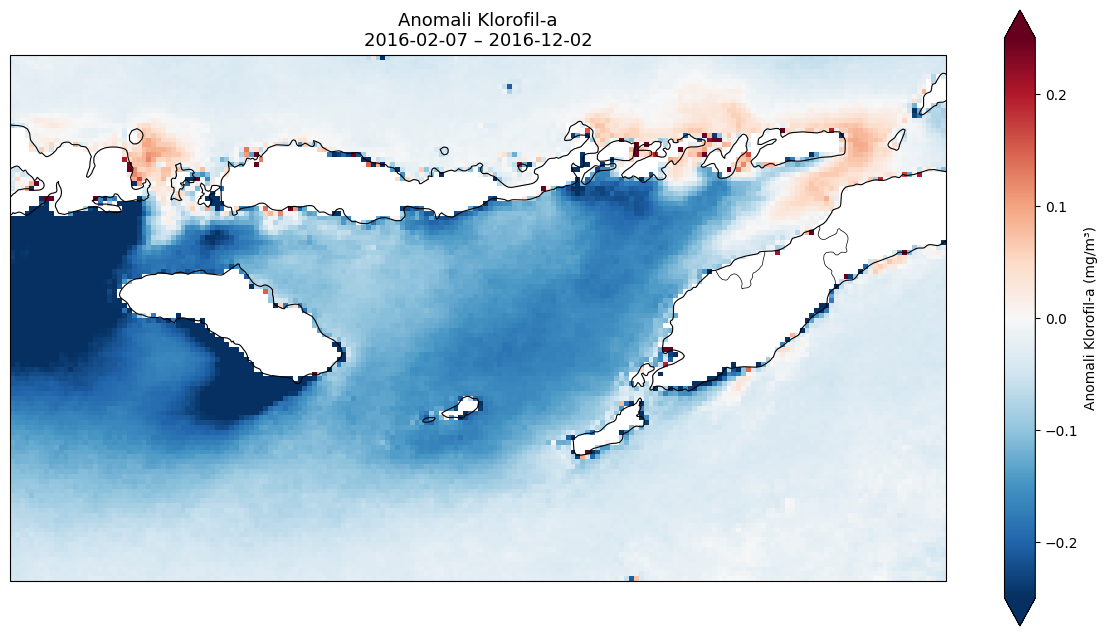

In [13]:
fig = plt.figure(figsize=(12, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

# BATAS KOORDINAT SESUAI GAMBAR
ax.set_extent([118, 126, -12, -7.5], crs=ccrs.PlateCarree())

limit = 0.25

chl_anomali.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    cbar_kwargs={
        "label": "Anomali Klorofil-a (mg/m³)",
        "shrink": 0.8
    }
)

ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

ax.set_title(
    f"Anomali Klorofil-a\n{tanggal_mulai} – {tanggal_akhir}",
    fontsize=13
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

# KE - 2


In [14]:
tanggal_mulai = "2016-01-08"
tanggal_akhir = "2016-01-30"

chl_periode = chl.sel(
    time=slice(tanggal_mulai, tanggal_akhir)
)

if chl_periode.sizes["time"] == 0:
    raise ValueError("Tidak terdapat data pada rentang waktu yang dipilih.")

print("Periode analisis:", tanggal_mulai, "sampai", tanggal_akhir)
print("Jumlah data harian:", chl_periode.sizes["time"])

Periode analisis: 2016-01-08 sampai 2016-01-30
Jumlah data harian: 23


In [15]:
chl_mean_grid = chl_periode.mean(
    dim="time",
    skipna=True
)

print("Perhitungan rata-rata setiap grid selesai (tanpa filter IQR).")
print("Dimensi hasil:", chl_mean_grid.dims)

Perhitungan rata-rata setiap grid selesai (tanpa filter IQR).
Dimensi hasil: ('lat', 'lon')


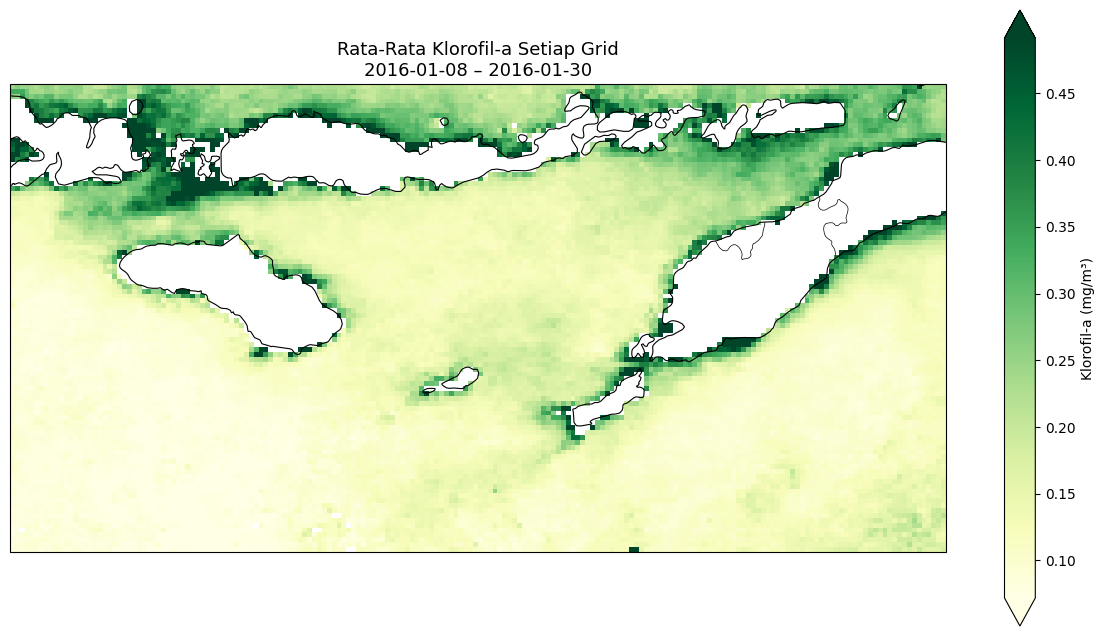

In [16]:
fig = plt.figure(figsize=(12, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

# BATAS KOORDINAT SESUAI GAMBAR
ax.set_extent([118, 126, -12, -8], crs=ccrs.PlateCarree())
    
chl_mean_grid.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="YlGn",
    robust=True,
    cbar_kwargs={
        "label": "Klorofil-a (mg/m³)",
        "shrink": 0.8
    }
)

ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

ax.set_title(
    f"Rata-Rata Klorofil-a Setiap Grid\n{tanggal_mulai} – {tanggal_akhir}",
    fontsize=13
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [17]:
# ==========================================
# CELL 7 - PERHITUNGAN ANOMALI KLOROFIL-A
# ==========================================

# Konversi tanggal menjadi datetime
tanggal_awal = pd.to_datetime(tanggal_mulai)
tanggal_akhir_dt = pd.to_datetime(tanggal_akhir)

# Pastikan rentang tanggal tidak terbalik
if tanggal_awal > tanggal_akhir_dt:
    raise ValueError("Tanggal mulai harus sebelum tanggal akhir.")

# Mengambil data historis untuk baseline
tahun_awal_baseline = int(chl.time.dt.year.min())
tahun_akhir_baseline = int(chl.time.dt.year.max())

# Mengambil bulan dan tanggal yang sama pada setiap tahun
bulan_awal = tanggal_awal.month
bulan_akhir = tanggal_akhir_dt.month

hari_awal = tanggal_awal.day
hari_akhir = tanggal_akhir_dt.day

mask_kalender = (
    (chl.time.dt.month >= bulan_awal) &
    (chl.time.dt.month <= bulan_akhir)
)

# Menangani periode yang melewati pergantian tahun
if bulan_awal > bulan_akhir:
    mask_kalender = (
        (chl.time.dt.month >= bulan_awal) |
        (chl.time.dt.month <= bulan_akhir)
    )

baseline_data = chl.where(mask_kalender, drop=True)

# Mengambil rentang tahun baseline
baseline_data = baseline_data.where(
    (baseline_data.time.dt.year >= tahun_awal_baseline) &
    (baseline_data.time.dt.year <= tahun_akhir_baseline),
    drop=True
)

# Menghitung rata-rata klimatologi setiap grid
baseline_mean = baseline_data.mean(
    dim="time",
    skipna=True
)

# Baseline tetap mengikuti logika notebook awal: bulan target pada seluruh tahun data,
# termasuk tahun target; hanya filtering IQR yang dihapus.

# Menghitung anomali setiap grid
chl_anomali = chl_mean_grid - baseline_mean

print("Perhitungan anomali selesai.")
print("Periode analisis:", tanggal_mulai, "-", tanggal_akhir)
print("Periode baseline:", tahun_awal_baseline, "-", tahun_akhir_baseline)
print("Jumlah grid:", chl_anomali.size)

Perhitungan anomali selesai.
Periode analisis: 2016-01-08 - 2016-01-30
Periode baseline: 2000 - 2020
Jumlah grid: 20736


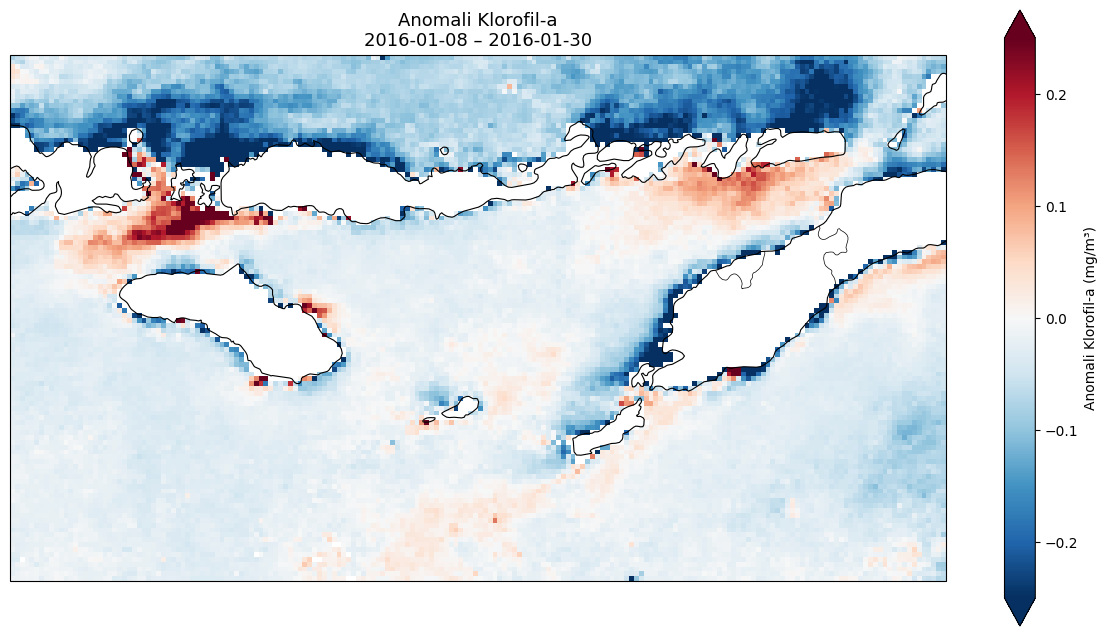

In [18]:
fig = plt.figure(figsize=(12, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

# BATAS KOORDINAT SESUAI GAMBAR
ax.set_extent([118, 126, -12, -7.5], crs=ccrs.PlateCarree())

limit = 0.25

chl_anomali.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    cbar_kwargs={
        "label": "Anomali Klorofil-a (mg/m³)",
        "shrink": 0.8
    }
)

ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

ax.set_title(
    f"Anomali Klorofil-a\n{tanggal_mulai} – {tanggal_akhir}",
    fontsize=13
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

# Ke - 3

In [19]:
tanggal_mulai = "2019-12-06"
tanggal_akhir = "2020-01-04"

chl_periode = chl.sel(
    time=slice(tanggal_mulai, tanggal_akhir)
)

if chl_periode.sizes["time"] == 0:
    raise ValueError("Tidak terdapat data pada rentang waktu yang dipilih.")

print("Periode analisis:", tanggal_mulai, "sampai", tanggal_akhir)
print("Jumlah data harian:", chl_periode.sizes["time"])

Periode analisis: 2019-12-06 sampai 2020-01-04
Jumlah data harian: 30


In [20]:
chl_mean_grid = chl_periode.mean(
    dim="time",
    skipna=True
)

print("Perhitungan rata-rata setiap grid selesai (tanpa filter IQR).")
print("Dimensi hasil:", chl_mean_grid.dims)

Perhitungan rata-rata setiap grid selesai (tanpa filter IQR).
Dimensi hasil: ('lat', 'lon')


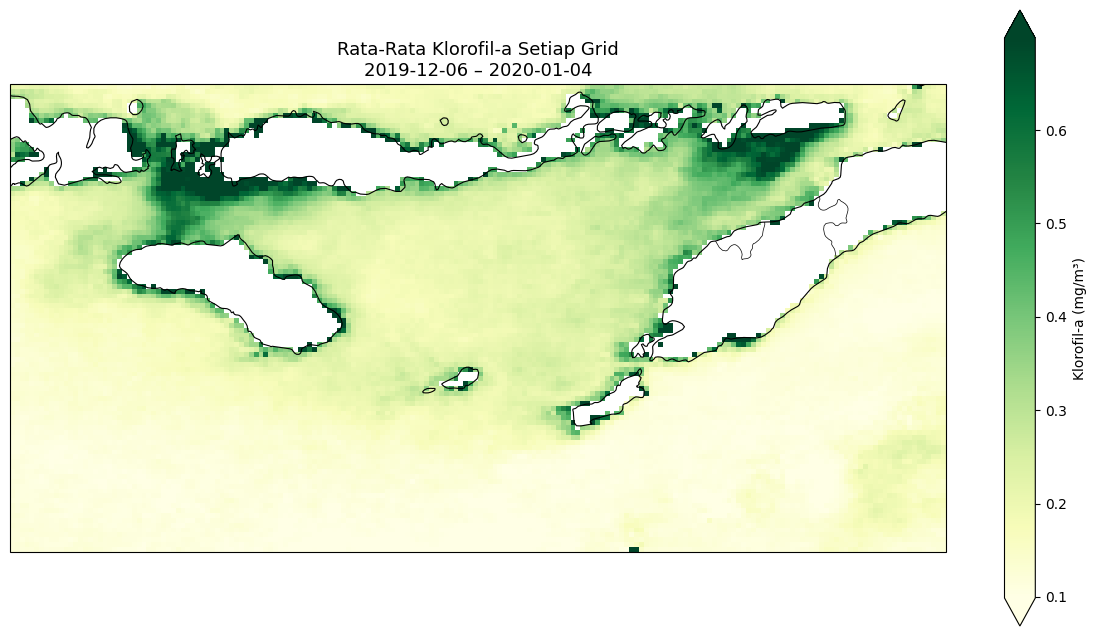

In [21]:
fig = plt.figure(figsize=(12, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

# BATAS KOORDINAT SESUAI GAMBAR
ax.set_extent([118, 126, -12, -8], crs=ccrs.PlateCarree())
    
chl_mean_grid.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="YlGn",
    robust=True,
    cbar_kwargs={
        "label": "Klorofil-a (mg/m³)",
        "shrink": 0.8
    }
)

ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

ax.set_title(
    f"Rata-Rata Klorofil-a Setiap Grid\n{tanggal_mulai} – {tanggal_akhir}",
    fontsize=13
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [22]:
# ==========================================
# CELL 7 - PERHITUNGAN ANOMALI KLOROFIL-A
# ==========================================

# Konversi tanggal menjadi datetime
tanggal_awal = pd.to_datetime(tanggal_mulai)
tanggal_akhir_dt = pd.to_datetime(tanggal_akhir)

# Pastikan rentang tanggal tidak terbalik
if tanggal_awal > tanggal_akhir_dt:
    raise ValueError("Tanggal mulai harus sebelum tanggal akhir.")

# Mengambil data historis untuk baseline
tahun_awal_baseline = int(chl.time.dt.year.min())
tahun_akhir_baseline = int(chl.time.dt.year.max())

# Mengambil bulan dan tanggal yang sama pada setiap tahun
bulan_awal = tanggal_awal.month
bulan_akhir = tanggal_akhir_dt.month

hari_awal = tanggal_awal.day
hari_akhir = tanggal_akhir_dt.day

mask_kalender = (
    (chl.time.dt.month >= bulan_awal) &
    (chl.time.dt.month <= bulan_akhir)
)

# Menangani periode yang melewati pergantian tahun
if bulan_awal > bulan_akhir:
    mask_kalender = (
        (chl.time.dt.month >= bulan_awal) |
        (chl.time.dt.month <= bulan_akhir)
    )

baseline_data = chl.where(mask_kalender, drop=True)

# Mengambil rentang tahun baseline
baseline_data = baseline_data.where(
    (baseline_data.time.dt.year >= tahun_awal_baseline) &
    (baseline_data.time.dt.year <= tahun_akhir_baseline),
    drop=True
)

# Menghitung rata-rata klimatologi setiap grid
baseline_mean = baseline_data.mean(
    dim="time",
    skipna=True
)

# Baseline tetap mengikuti logika notebook awal: bulan target pada seluruh tahun data,
# termasuk tahun target; hanya filtering IQR yang dihapus.

# Menghitung anomali setiap grid
chl_anomali = chl_mean_grid - baseline_mean

print("Perhitungan anomali selesai.")
print("Periode analisis:", tanggal_mulai, "-", tanggal_akhir)
print("Periode baseline:", tahun_awal_baseline, "-", tahun_akhir_baseline)
print("Jumlah grid:", chl_anomali.size)

Perhitungan anomali selesai.
Periode analisis: 2019-12-06 - 2020-01-04
Periode baseline: 2000 - 2020
Jumlah grid: 20736


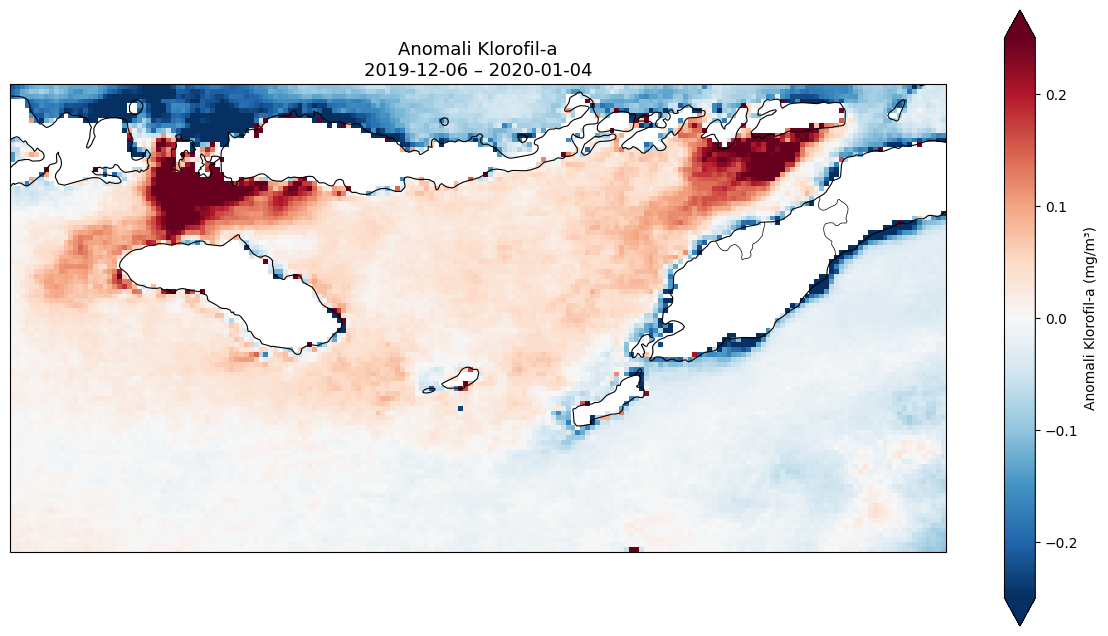

In [23]:
fig = plt.figure(figsize=(12, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

# BATAS KOORDINAT SESUAI GAMBAR
ax.set_extent([118, 126, -12, -8], crs=ccrs.PlateCarree())

limit = 0.25

chl_anomali.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    cbar_kwargs={
        "label": "Anomali Klorofil-a (mg/m³)",
        "shrink": 0.8
    }
)

ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

ax.set_title(
    f"Anomali Klorofil-a\n{tanggal_mulai} – {tanggal_akhir}",
    fontsize=13
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

# Ke - 4

In [24]:
tanggal_mulai = "2009-01-08"
tanggal_akhir = "2009-01-30"

chl_periode = chl.sel(
    time=slice(tanggal_mulai, tanggal_akhir)
)

if chl_periode.sizes["time"] == 0:
    raise ValueError("Tidak terdapat data pada rentang waktu yang dipilih.")

print("Periode analisis:", tanggal_mulai, "sampai", tanggal_akhir)
print("Jumlah data harian:", chl_periode.sizes["time"])

Periode analisis: 2009-01-08 sampai 2009-01-30
Jumlah data harian: 23


In [25]:
chl_mean_grid = chl_periode.mean(
    dim="time",
    skipna=True
)

print("Perhitungan rata-rata setiap grid selesai (tanpa filter IQR).")
print("Dimensi hasil:", chl_mean_grid.dims)

Perhitungan rata-rata setiap grid selesai (tanpa filter IQR).
Dimensi hasil: ('lat', 'lon')


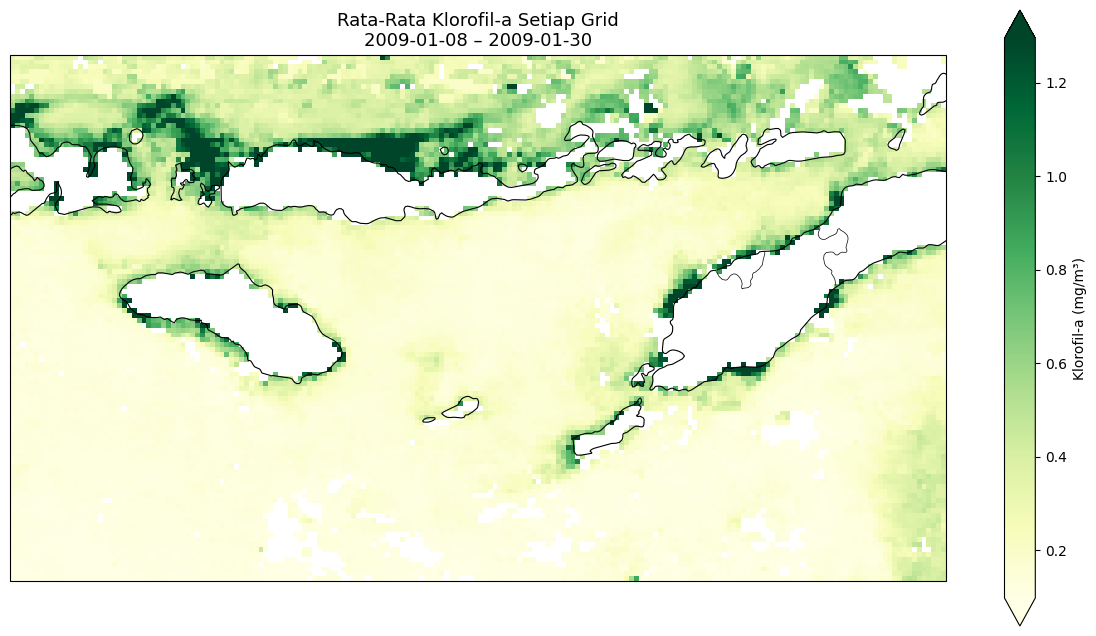

In [26]:
fig = plt.figure(figsize=(12, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

# BATAS KOORDINAT SESUAI GAMBAR
ax.set_extent([118, 126, -12, -7.5], crs=ccrs.PlateCarree())
    
chl_mean_grid.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="YlGn",
    robust=True,
    cbar_kwargs={
        "label": "Klorofil-a (mg/m³)",
        "shrink": 0.8
    }
)

ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

ax.set_title(
    f"Rata-Rata Klorofil-a Setiap Grid\n{tanggal_mulai} – {tanggal_akhir}",
    fontsize=13
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [27]:
# ==========================================
# CELL 7 - PERHITUNGAN ANOMALI KLOROFIL-A
# ==========================================

# Konversi tanggal menjadi datetime
tanggal_awal = pd.to_datetime(tanggal_mulai)
tanggal_akhir_dt = pd.to_datetime(tanggal_akhir)

# Pastikan rentang tanggal tidak terbalik
if tanggal_awal > tanggal_akhir_dt:
    raise ValueError("Tanggal mulai harus sebelum tanggal akhir.")

# Mengambil data historis untuk baseline
tahun_awal_baseline = int(chl.time.dt.year.min())
tahun_akhir_baseline = int(chl.time.dt.year.max())

# Mengambil bulan dan tanggal yang sama pada setiap tahun
bulan_awal = tanggal_awal.month
bulan_akhir = tanggal_akhir_dt.month

hari_awal = tanggal_awal.day
hari_akhir = tanggal_akhir_dt.day

mask_kalender = (
    (chl.time.dt.month >= bulan_awal) &
    (chl.time.dt.month <= bulan_akhir)
)

# Menangani periode yang melewati pergantian tahun
if bulan_awal > bulan_akhir:
    mask_kalender = (
        (chl.time.dt.month >= bulan_awal) |
        (chl.time.dt.month <= bulan_akhir)
    )

baseline_data = chl.where(mask_kalender, drop=True)

# Mengambil rentang tahun baseline
baseline_data = baseline_data.where(
    (baseline_data.time.dt.year >= tahun_awal_baseline) &
    (baseline_data.time.dt.year <= tahun_akhir_baseline),
    drop=True
)

# Menghitung rata-rata klimatologi setiap grid
baseline_mean = baseline_data.mean(
    dim="time",
    skipna=True
)

# Baseline tetap mengikuti logika notebook awal: bulan target pada seluruh tahun data,
# termasuk tahun target; hanya filtering IQR yang dihapus.

# Menghitung anomali setiap grid
chl_anomali = chl_mean_grid - baseline_mean

print("Perhitungan anomali selesai.")
print("Periode analisis:", tanggal_mulai, "-", tanggal_akhir)
print("Periode baseline:", tahun_awal_baseline, "-", tahun_akhir_baseline)
print("Jumlah grid:", chl_anomali.size)

Perhitungan anomali selesai.
Periode analisis: 2009-01-08 - 2009-01-30
Periode baseline: 2000 - 2020
Jumlah grid: 20736


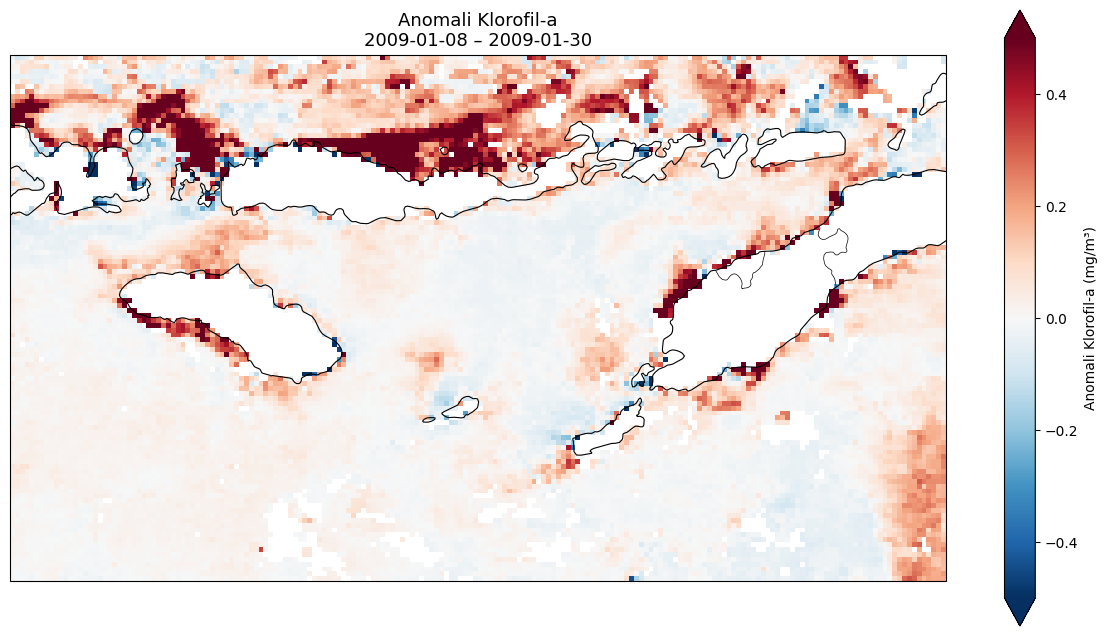

In [28]:
fig = plt.figure(figsize=(12, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

# BATAS KOORDINAT SESUAI GAMBAR
ax.set_extent([118, 126, -12, -7.5], crs=ccrs.PlateCarree())
    
limit = 0.5

chl_anomali.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    cbar_kwargs={
        "label": "Anomali Klorofil-a (mg/m³)",
        "shrink": 0.8
    }
)

ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

ax.set_title(
    f"Anomali Klorofil-a\n{tanggal_mulai} – {tanggal_akhir}",
    fontsize=13
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

# Ke - 5

In [29]:
tanggal_mulai = "2011-02-07"
tanggal_akhir = "2011-12-02"

chl_periode = chl.sel(
    time=slice(tanggal_mulai, tanggal_akhir)
)

if chl_periode.sizes["time"] == 0:
    raise ValueError("Tidak terdapat data pada rentang waktu yang dipilih.")

print("Periode analisis:", tanggal_mulai, "sampai", tanggal_akhir)
print("Jumlah data harian:", chl_periode.sizes["time"])

Periode analisis: 2011-02-07 sampai 2011-12-02
Jumlah data harian: 299


In [30]:
chl_mean_grid = chl_periode.mean(
    dim="time",
    skipna=True
)

print("Perhitungan rata-rata setiap grid selesai (tanpa filter IQR).")
print("Dimensi hasil:", chl_mean_grid.dims)

Perhitungan rata-rata setiap grid selesai (tanpa filter IQR).
Dimensi hasil: ('lat', 'lon')


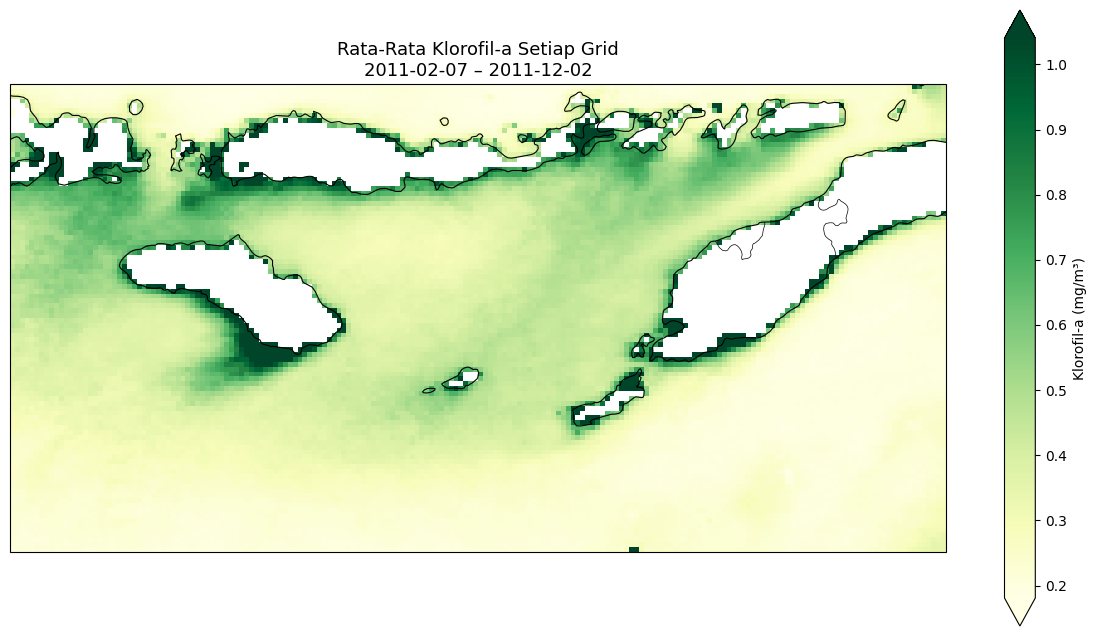

In [31]:
fig = plt.figure(figsize=(12, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

# BATAS KOORDINAT SESUAI GAMBAR
ax.set_extent([118, 126, -12, -8], crs=ccrs.PlateCarree())

chl_mean_grid.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="YlGn",
    robust=True,
    cbar_kwargs={
        "label": "Klorofil-a (mg/m³)",
        "shrink": 0.8
    }
)

ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

ax.set_title(
    f"Rata-Rata Klorofil-a Setiap Grid\n{tanggal_mulai} – {tanggal_akhir}",
    fontsize=13
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [32]:
# ==========================================
# CELL 7 - PERHITUNGAN ANOMALI KLOROFIL-A
# ==========================================

# Konversi tanggal menjadi datetime
tanggal_awal = pd.to_datetime(tanggal_mulai)
tanggal_akhir_dt = pd.to_datetime(tanggal_akhir)

# Pastikan rentang tanggal tidak terbalik
if tanggal_awal > tanggal_akhir_dt:
    raise ValueError("Tanggal mulai harus sebelum tanggal akhir.")

# Mengambil data historis untuk baseline
tahun_awal_baseline = int(chl.time.dt.year.min())
tahun_akhir_baseline = int(chl.time.dt.year.max())

# Mengambil bulan dan tanggal yang sama pada setiap tahun
bulan_awal = tanggal_awal.month
bulan_akhir = tanggal_akhir_dt.month

hari_awal = tanggal_awal.day
hari_akhir = tanggal_akhir_dt.day

mask_kalender = (
    (chl.time.dt.month >= bulan_awal) &
    (chl.time.dt.month <= bulan_akhir)
)

# Menangani periode yang melewati pergantian tahun
if bulan_awal > bulan_akhir:
    mask_kalender = (
        (chl.time.dt.month >= bulan_awal) |
        (chl.time.dt.month <= bulan_akhir)
    )

baseline_data = chl.where(mask_kalender, drop=True)

# Mengambil rentang tahun baseline
baseline_data = baseline_data.where(
    (baseline_data.time.dt.year >= tahun_awal_baseline) &
    (baseline_data.time.dt.year <= tahun_akhir_baseline),
    drop=True
)

# Menghitung rata-rata klimatologi setiap grid
baseline_mean = baseline_data.mean(
    dim="time",
    skipna=True
)

# Baseline tetap mengikuti logika notebook awal: bulan target pada seluruh tahun data,
# termasuk tahun target; hanya filtering IQR yang dihapus.

# Menghitung anomali setiap grid
chl_anomali = chl_mean_grid - baseline_mean

print("Perhitungan anomali selesai.")
print("Periode analisis:", tanggal_mulai, "-", tanggal_akhir)
print("Periode baseline:", tahun_awal_baseline, "-", tahun_akhir_baseline)
print("Jumlah grid:", chl_anomali.size)

Perhitungan anomali selesai.
Periode analisis: 2011-02-07 - 2011-12-02
Periode baseline: 2000 - 2020
Jumlah grid: 20736


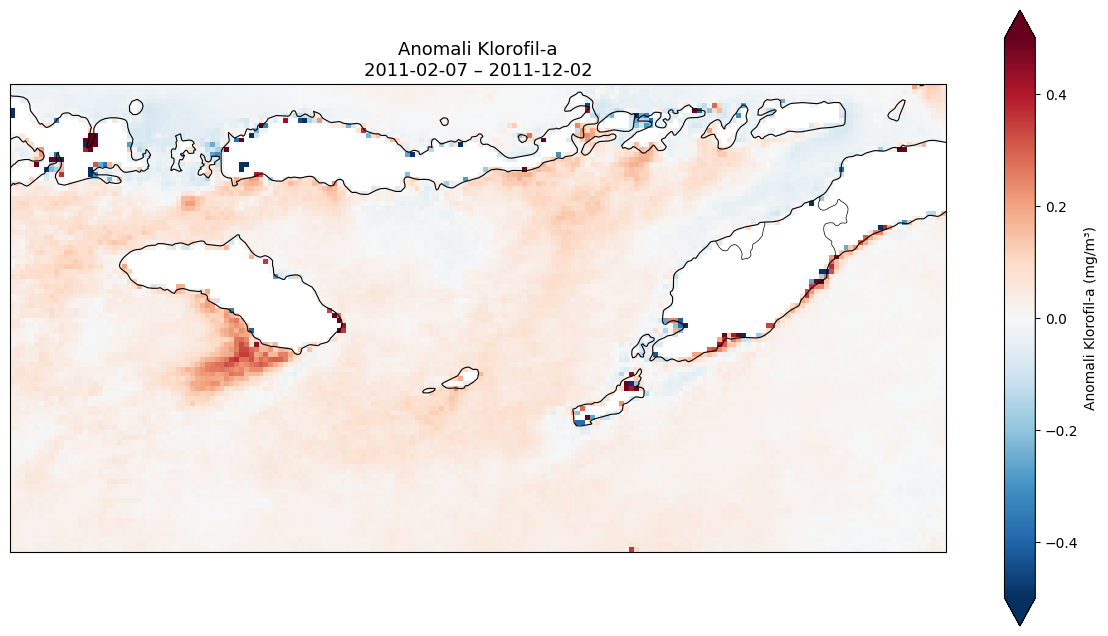

In [33]:
fig = plt.figure(figsize=(12, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

# BATAS KOORDINAT SESUAI GAMBAR
ax.set_extent([118, 126, -12, -8], crs=ccrs.PlateCarree())
    
limit = 0.5

chl_anomali.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    cbar_kwargs={
        "label": "Anomali Klorofil-a (mg/m³)",
        "shrink": 0.8
    }
)

ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

ax.set_title(
    f"Anomali Klorofil-a\n{tanggal_mulai} – {tanggal_akhir}",
    fontsize=13
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

# Ke - 6

In [34]:
tanggal_mulai = "2000-12-06"
tanggal_akhir = "2001-01-04"

chl_periode = chl.sel(
    time=slice(tanggal_mulai, tanggal_akhir)
)

if chl_periode.sizes["time"] == 0:
    raise ValueError("Tidak terdapat data pada rentang waktu yang dipilih.")

print("Periode analisis:", tanggal_mulai, "sampai", tanggal_akhir)
print("Jumlah data harian:", chl_periode.sizes["time"])

Periode analisis: 2000-12-06 sampai 2001-01-04
Jumlah data harian: 30


In [35]:
chl_mean_grid = chl_periode.mean(
    dim="time",
    skipna=True
)

print("Perhitungan rata-rata setiap grid selesai (tanpa filter IQR).")
print("Dimensi hasil:", chl_mean_grid.dims)

Perhitungan rata-rata setiap grid selesai (tanpa filter IQR).
Dimensi hasil: ('lat', 'lon')


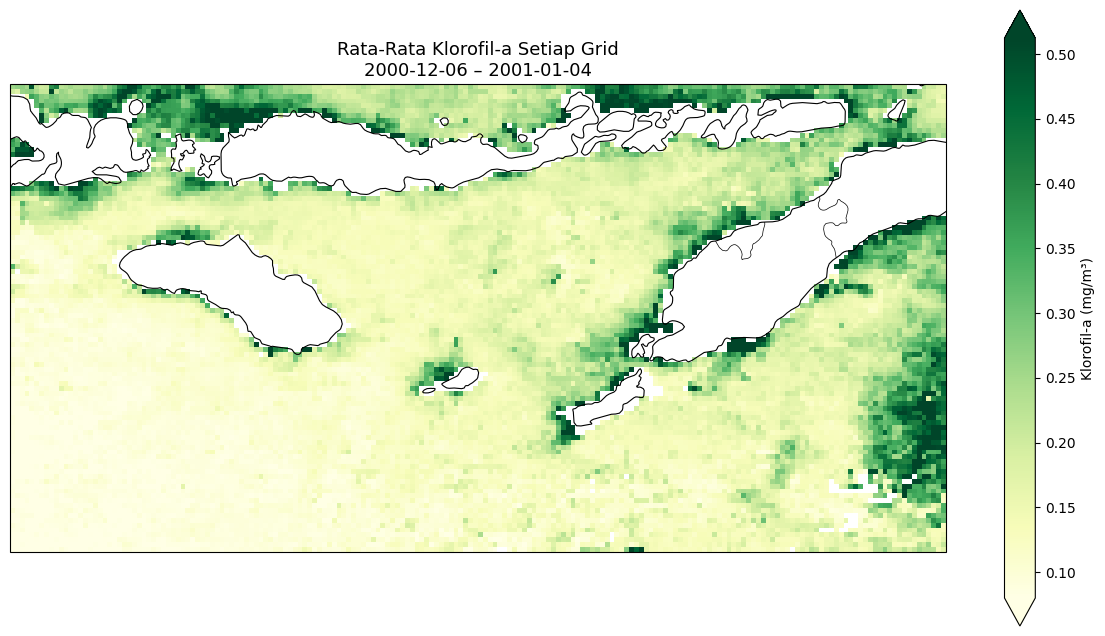

In [36]:
fig = plt.figure(figsize=(12, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

# BATAS KOORDINAT SESUAI GAMBAR
ax.set_extent([118, 126, -12, -8], crs=ccrs.PlateCarree())
    
chl_mean_grid.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="YlGn",
    robust=True,
    cbar_kwargs={
        "label": "Klorofil-a (mg/m³)",
        "shrink": 0.8
    }
)

ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

ax.set_title(
    f"Rata-Rata Klorofil-a Setiap Grid\n{tanggal_mulai} – {tanggal_akhir}",
    fontsize=13
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [37]:
# ==========================================
# CELL 7 - PERHITUNGAN ANOMALI KLOROFIL-A
# ==========================================

# Konversi tanggal menjadi datetime
tanggal_awal = pd.to_datetime(tanggal_mulai)
tanggal_akhir_dt = pd.to_datetime(tanggal_akhir)

# Pastikan rentang tanggal tidak terbalik
if tanggal_awal > tanggal_akhir_dt:
    raise ValueError("Tanggal mulai harus sebelum tanggal akhir.")

# Mengambil data historis untuk baseline
tahun_awal_baseline = int(chl.time.dt.year.min())
tahun_akhir_baseline = int(chl.time.dt.year.max())

# Mengambil bulan dan tanggal yang sama pada setiap tahun
bulan_awal = tanggal_awal.month
bulan_akhir = tanggal_akhir_dt.month

hari_awal = tanggal_awal.day
hari_akhir = tanggal_akhir_dt.day

mask_kalender = (
    (chl.time.dt.month >= bulan_awal) &
    (chl.time.dt.month <= bulan_akhir)
)

# Menangani periode yang melewati pergantian tahun
if bulan_awal > bulan_akhir:
    mask_kalender = (
        (chl.time.dt.month >= bulan_awal) |
        (chl.time.dt.month <= bulan_akhir)
    )

baseline_data = chl.where(mask_kalender, drop=True)

# Mengambil rentang tahun baseline
baseline_data = baseline_data.where(
    (baseline_data.time.dt.year >= tahun_awal_baseline) &
    (baseline_data.time.dt.year <= tahun_akhir_baseline),
    drop=True
)

# Menghitung rata-rata klimatologi setiap grid
baseline_mean = baseline_data.mean(
    dim="time",
    skipna=True
)

# Baseline tetap mengikuti logika notebook awal: bulan target pada seluruh tahun data,
# termasuk tahun target; hanya filtering IQR yang dihapus.

# Menghitung anomali setiap grid
chl_anomali = chl_mean_grid - baseline_mean

print("Perhitungan anomali selesai.")
print("Periode analisis:", tanggal_mulai, "-", tanggal_akhir)
print("Periode baseline:", tahun_awal_baseline, "-", tahun_akhir_baseline)
print("Jumlah grid:", chl_anomali.size)

Perhitungan anomali selesai.
Periode analisis: 2000-12-06 - 2001-01-04
Periode baseline: 2000 - 2020
Jumlah grid: 20736


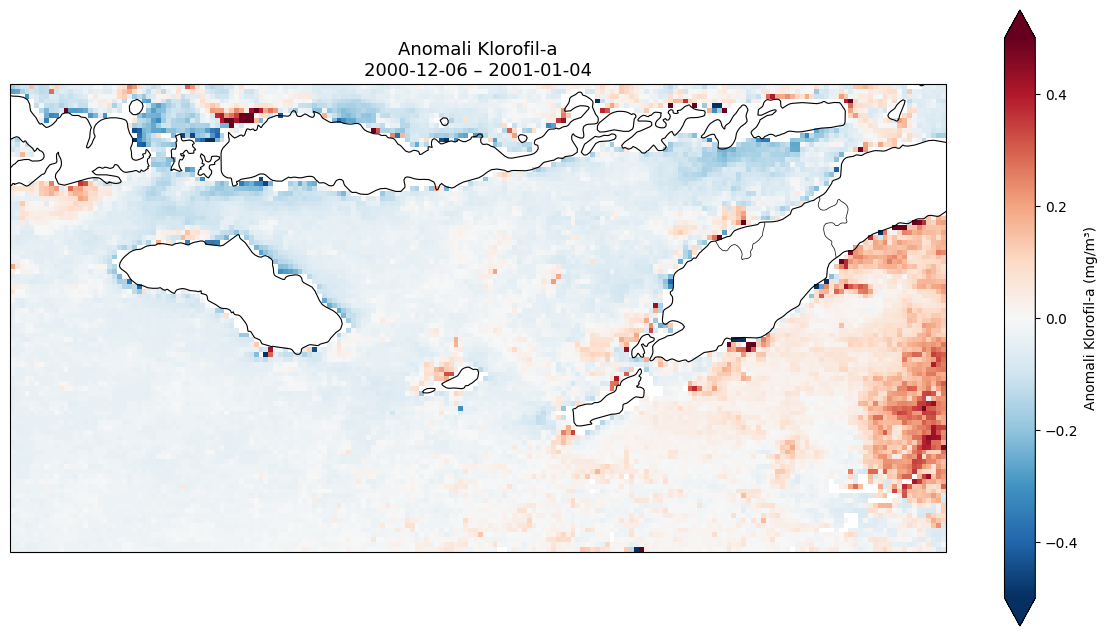

In [38]:
fig = plt.figure(figsize=(12, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

# BATAS KOORDINAT SESUAI GAMBAR
ax.set_extent([118, 126, -12, -8], crs=ccrs.PlateCarree())
    
limit = 0.5

chl_anomali.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    cbar_kwargs={
        "label": "Anomali Klorofil-a (mg/m³)",
        "shrink": 0.8
    }
)

ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

ax.set_title(
    f"Anomali Klorofil-a\n{tanggal_mulai} – {tanggal_akhir}",
    fontsize=13
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

# Perbandingan Rata-rata Anomali Klorofil dan Rata-rata Nilai Klorofil

In [39]:

# ============================================================
# TABEL PERBANDINGAN RATA-RATA KLOROFIL-A DAN ANOMALI
# UNTUK 6 PERIODE ANALISIS
# WILAYAH: 118-126 BT DAN 8-12 LS
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# 1. MENGGUNAKAN DATA KLOROFIL-A YANG SUDAH TERSEDIA
# ------------------------------------------------------------

# Tidak membaca ulang data.nc.
# Menggunakan variabel chl dari proses sebelumnya.

if "chl" not in globals():
    raise NameError(
        "Variabel chl belum tersedia. Jalankan terlebih dahulu "
        "cell pembacaan data klorofil-a."
    )

# Batas koordinat wilayah analisis
lon_min, lon_max = 118, 126
lat_min, lat_max = -12, -8

# Mendeteksi nama koordinat
lon_name = next(
    (c for c in ["lon", "longitude"] if c in chl.coords),
    None
)

lat_name = next(
    (c for c in ["lat", "latitude"] if c in chl.coords),
    None
)

if lon_name is None or lat_name is None:
    raise ValueError("Koordinat longitude/latitude tidak ditemukan.")

# Memastikan data yang digunakan sudah terpotong secara spasial
chl_analisis = chl.where(
    (chl[lon_name] >= lon_min) &
    (chl[lon_name] <= lon_max) &
    (chl[lat_name] >= lat_min) &
    (chl[lat_name] <= lat_max),
    drop=True
)

print("Data klorofil-a berhasil disiapkan.")
print("Wilayah analisis:")
print(f"Longitude: {lon_min} - {lon_max} BT")
print(f"Latitude : {lat_min} - {lat_max} LS")
print("Dimensi data:", chl_analisis.shape)

print(
    "Rentang data:",
    pd.to_datetime(chl_analisis.time.values).min(),
    "hingga",
    pd.to_datetime(chl_analisis.time.values).max()
)


# ------------------------------------------------------------
# 2. DAFTAR PERIODE ANALISIS
# ------------------------------------------------------------

daftar_periode = [
    {
        "Periode": "Periode 1",
        "Tanggal Awal": "2016-02-07",
        "Tanggal Akhir": "2016-12-02"
    },
    {
        "Periode": "Periode 2",
        "Tanggal Awal": "2016-01-08",
        "Tanggal Akhir": "2016-01-30"
    },
    {
        "Periode": "Periode 3",
        "Tanggal Awal": "2019-12-06",
        "Tanggal Akhir": "2020-01-04"
    },
    {
        "Periode": "Periode 4",
        "Tanggal Awal": "2009-01-08",
        "Tanggal Akhir": "2009-01-30"
    },
    {
        "Periode": "Periode 5",
        "Tanggal Awal": "2011-02-07",
        "Tanggal Akhir": "2011-12-02"
    },
    {
        "Periode": "Periode 6",
        "Tanggal Awal": "2000-12-06",
        "Tanggal Akhir": "2001-01-04"
    }
]


# ------------------------------------------------------------
# 3. PERHITUNGAN RATA-RATA KLOROFIL-A DAN ANOMALI
# ------------------------------------------------------------

hasil_perbandingan = []

# Tahun baseline berdasarkan keseluruhan rentang waktu
# pada data spasial yang sudah dipotong
tahun_awal_baseline = int(
    chl_analisis.time.dt.year.min()
)

tahun_akhir_baseline = int(
    chl_analisis.time.dt.year.max()
)

for periode in daftar_periode:

    nama_periode = periode["Periode"]

    tanggal_awal = pd.to_datetime(
        periode["Tanggal Awal"]
    )

    tanggal_akhir = pd.to_datetime(
        periode["Tanggal Akhir"]
    )

    # --------------------------------------------------------
    # A. MENGAMBIL DATA SESUAI PERIODE ANALISIS
    # --------------------------------------------------------

    chl_periode = chl_analisis.sel(
        time=slice(tanggal_awal, tanggal_akhir)
    )

    if chl_periode.sizes["time"] == 0:
        print(
            f"{nama_periode}: data tidak tersedia, dilewati."
        )
        continue

    # Rata-rata temporal setiap grid
    chl_mean_grid = chl_periode.mean(
        dim="time",
        skipna=True
    )

    # --------------------------------------------------------
    # B. MENENTUKAN BULAN BASELINE
    # --------------------------------------------------------

    bulan_awal = tanggal_awal.month
    bulan_akhir = tanggal_akhir.month

    # Periode tidak melewati pergantian tahun
    if bulan_awal <= bulan_akhir:

        mask_kalender = (
            (chl_analisis.time.dt.month >= bulan_awal) &
            (chl_analisis.time.dt.month <= bulan_akhir)
        )

    # Periode melewati pergantian tahun
    else:

        mask_kalender = (
            (chl_analisis.time.dt.month >= bulan_awal) |
            (chl_analisis.time.dt.month <= bulan_akhir)
        )

    # --------------------------------------------------------
    # C. MENGAMBIL DATA BASELINE
    # --------------------------------------------------------

    baseline_data = chl_analisis.where(
        mask_kalender,
        drop=True
    )

    # Menggunakan seluruh tahun data
    baseline_data = baseline_data.where(
        (baseline_data.time.dt.year >= tahun_awal_baseline) &
        (baseline_data.time.dt.year <= tahun_akhir_baseline),
        drop=True
    )

    # Rata-rata klimatologi setiap grid
    baseline_mean = baseline_data.mean(
        dim="time",
        skipna=True
    )

    # --------------------------------------------------------
    # D. MENGHITUNG ANOMALI KLOROFIL-A
    # --------------------------------------------------------

    chl_anomali = chl_mean_grid - baseline_mean

    # --------------------------------------------------------
    # E. MENGHITUNG RATA-RATA SPASIAL
    # --------------------------------------------------------

    # Rata-rata klorofil-a periode analisis
    rata_rata_chl = chl_mean_grid.mean(
        skipna=True
    ).item()

    # Rata-rata anomali klorofil-a
    rata_rata_anomali = chl_anomali.mean(
        skipna=True
    ).item()

    # --------------------------------------------------------
    # F. MENYIMPAN HASIL
    # --------------------------------------------------------

    hasil_perbandingan.append({
        "Periode": nama_periode,
        "Tanggal Awal": tanggal_awal.strftime("%Y-%m-%d"),
        "Tanggal Akhir": tanggal_akhir.strftime("%Y-%m-%d"),
        "Rata-rata Klorofil-a (mg/m³)": rata_rata_chl,
        "Rata-rata Anomali Klorofil-a (mg/m³)": rata_rata_anomali
    })

    print(f"Perhitungan {nama_periode} selesai.")


# ------------------------------------------------------------
# 4. MEMBUAT TABEL OUTPUT
# ------------------------------------------------------------

tabel_perbandingan = pd.DataFrame(
    hasil_perbandingan
)

# Membulatkan nilai hingga 4 angka desimal
kolom_numerik = [
    "Rata-rata Klorofil-a (mg/m³)",
    "Rata-rata Anomali Klorofil-a (mg/m³)"
]

tabel_perbandingan[kolom_numerik] = (
    tabel_perbandingan[kolom_numerik].round(4)
)


# ------------------------------------------------------------
# 5. MENAMPILKAN TABEL
# ------------------------------------------------------------

print(
    "\nTABEL PERBANDINGAN RATA-RATA KLOROFIL-A "
    "DAN ANOMALI"
)

print("Wilayah: 118-126 BT dan 8-12 LS")

display(tabel_perbandingan)


Data klorofil-a berhasil disiapkan.
Wilayah analisis:
Longitude: 118 - 126 BT
Latitude : -12 - -8 LS
Dimensi data: (7669, 96, 192)
Rentang data: 2000-01-01 00:00:00 hingga 2020-12-31 00:00:00
Perhitungan Periode 1 selesai.
Perhitungan Periode 2 selesai.
Perhitungan Periode 3 selesai.
Perhitungan Periode 4 selesai.
Perhitungan Periode 5 selesai.
Perhitungan Periode 6 selesai.

TABEL PERBANDINGAN RATA-RATA KLOROFIL-A DAN ANOMALI
Wilayah: 118-126 BT dan 8-12 LS


,Periode,Tanggal Awal,Tanggal Akhir,Rata-rata Klorofil-a (mg/m³),Rata-rata Anomali Klorofil-a (mg/m³)
0,Periode 1,2016-02-07,2016-12-02,0.2511,-0.0913
1,Periode 2,2016-01-08,2016-01-30,0.1704,-0.0348
2,Periode 3,2019-12-06,2020-01-04,0.2214,-0.0008
3,Periode 4,2009-01-08,2009-01-30,0.2848,0.0578
4,Periode 5,2011-02-07,2011-12-02,0.4061,0.0274
5,Periode 6,2000-12-06,2001-01-04,0.1845,-0.0108
